# Step 9 — only the features KNHANES also has, leave-one-cycle-out

Before testing on KNHANES (Korea), measure what is lost by keeping only the features that have a KNHANES counterpart. Same design as step 1 (`nhanes/loco.py`, `run_loco`): LOCO over the 7 NHANES cycles, inner LOCO for tuning, elastic net and XGBoost, outcome PHQ-9 ≥ 10 (KNHANES uses the PHQ-9 too).

The features come from `docs/knhanes_mapping.csv` (the inventory in `docs/external_data.md`, section 6):

- **k125:** all 125 features with a KNHANES counterpart.
- **k114:** the 114 of them that KNHANES has in both 2014 and 2016 (the years with the PHQ-9 so far).

The features are used as NHANES defines them. Converting them to the KNHANES definitions (coarser income bands, fasting labs, one day of diet) can only lose more, so these numbers are an upper bound for the external test.

**Output:** `$NHANES_WORK/modeling/step9_knhanes_features/{k125,k114}/` with the same files as step 1. The comparison with all 317 features reads `$NHANES_WORK/modeling/step1/`.

`RUN = True` retrains (about 1 hour per feature set on 4 threads; the elastic net takes most of it); `QUICK = True` with it runs one outer fold with the smallest grids. `RUN = False` only shows the saved results.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import RESULTS  # noqa: E402

RUN = False    # True: retrain and overwrite $NHANES_WORK/modeling/step9_knhanes_features
QUICK = False  # with RUN: one outer fold, smallest grids
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
QUICK = QUICK or os.environ.get("NHANES_QUICK") == "1"
OUT = RESULTS / "step9_knhanes_features"

mapping = pd.read_csv(ROOT / "docs" / "knhanes_mapping.csv")
SETS = {"k125": list(mapping.feature), "k114": list(mapping.feature[mapping.years == "both"])}
print({k: len(v) for k, v in SETS.items()})

{'k125': 125, 'k114': 114}


## Features kept, by kind

In [2]:
kind = mapping.assign(group=mapping.feature.str.extract(r"^(LBX|LBD|URX|BPX|BMX|DR_|DR)", expand=False)
                      .map({"LBX": "labs", "LBD": "labs", "URX": "labs", "BPX": "blood pressure",
                            "BMX": "body measures", "DR_": "diet", "DR": "diet"}).fillna("questionnaire"))
display(pd.crosstab(kind.group, kind.years.map({"both": "2014 and 2016", "2016": "2016 only"}), margins=True))

years,2014 and 2016,2016 only,All
group,,,
blood pressure,8,0,8
body measures,4,0,4
diet,22,8,30
labs,20,1,21
questionnaire,60,2,62
All,114,11,125


## Run

In [3]:
if RUN:
    from nhanes.loco import FEAT, NOT_FEATURES, run_loco
    data = pd.read_csv(FEAT / "features_2005_2018.csv.gz")
    dic = pd.read_csv(FEAT / "feature_dictionary.csv").set_index("column").type.to_dict()
    for name, feats in SETS.items():
        print(f"=== {name}: {len(feats)} features")
        run_loco(data[NOT_FEATURES + feats], dic, OUT / name, QUICK,
                 title=f"leave-one-cycle-out, outcome PHQ-9 >= 10, {len(feats)} features with a KNHANES counterpart")

## Results

In [4]:
for name in SETS:
    print(f"=== {name}")
    print((OUT / name / "report.txt").read_text())

=== k125
leave-one-cycle-out, outcome PHQ-9 >= 10, 125 features with a KNHANES counterpart

mean (sd) over test cycles, each cycle weighted equally:
         auroc        auroc_weighted         auprc         brier       
          mean    std           mean    std   mean    std   mean    std
model                                                                  
logreg   0.838  0.014          0.842  0.018  0.400  0.039  0.157  0.004
xgboost  0.838  0.013          0.842  0.018  0.403  0.035  0.149  0.003

AUROC of all out-of-cycle predictions pooled:
model
logreg     0.838
xgboost    0.838

per test cycle:
  model test_cycle  auroc  auroc_weighted  auprc  brier    n  prevalence  minutes
 logreg    2005-06  0.847           0.860  0.378  0.153 3975       0.062      2.8
xgboost    2005-06  0.849           0.859  0.414  0.146 3975       0.062      0.4
 logreg    2007-08  0.854           0.857  0.454  0.153 5104       0.098      2.9
xgboost    2007-08  0.851           0.854  0.444  0.151 510

Mean AUROC over the 7 test cycles: all 317 features (step 1) against the two KNHANES sets.

In [5]:
runs = {"all 317": RESULTS / "step1", **{f"{k} ({len(v)})": OUT / k for k, v in SETS.items()}}
met = pd.concat([pd.read_csv(p / "metrics.csv").assign(features=k) for k, p in runs.items()
                 if (p / "metrics.csv").is_file()], ignore_index=True)
cycles = sorted(set.intersection(*[set(g.test_cycle) for _, g in met.groupby("features")]))
met = met[met.test_cycle.isin(cycles)]
table = (met.groupby(["model", "features"], sort=False).auroc.agg(mean="mean", sd="std").round(3)
         .unstack("model").swaplevel(axis=1).sort_index(axis=1))
display(table)
piv = met.pivot_table(index=["model", "test_cycle"], columns="features", values="auroc")
diff = piv.drop(columns="all 317").sub(piv["all 317"], axis=0)
print("AUROC change against all 317 features, over test cycles:")
display(diff.groupby(level="model").agg(["mean", "min", "max"]).round(3))

model      logreg        xgboost       
             mean     sd    mean     sd
features                               
all 317     0.874  0.011   0.871  0.010
k125 (125)  0.838  0.014   0.838  0.013
k114 (114)  0.834  0.013   0.833  0.011

AUROC change against all 317 features, over test cycles:


features k114 (114)               k125 (125)              
               mean    min    max       mean    min    max
model                                                     
logreg       -0.039 -0.050 -0.029     -0.036 -0.048 -0.023
xgboost      -0.038 -0.049 -0.028     -0.033 -0.049 -0.021

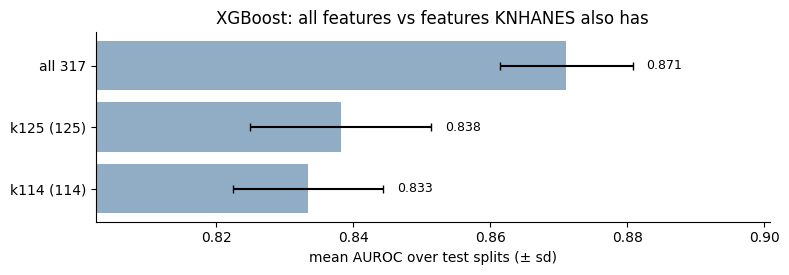

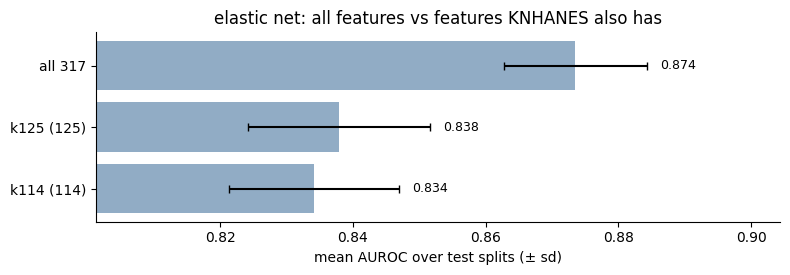

In [6]:
for model, name in [("xgboost", "XGBoost"), ("logreg", "elastic net")]:
    s = plots.summarise(met[met.model == model], by="features", order=list(runs))
    plots.mean_auroc_bars(s[s["mean"].notna()], title=f"{name}: all features vs features KNHANES also has")
    plots.show()

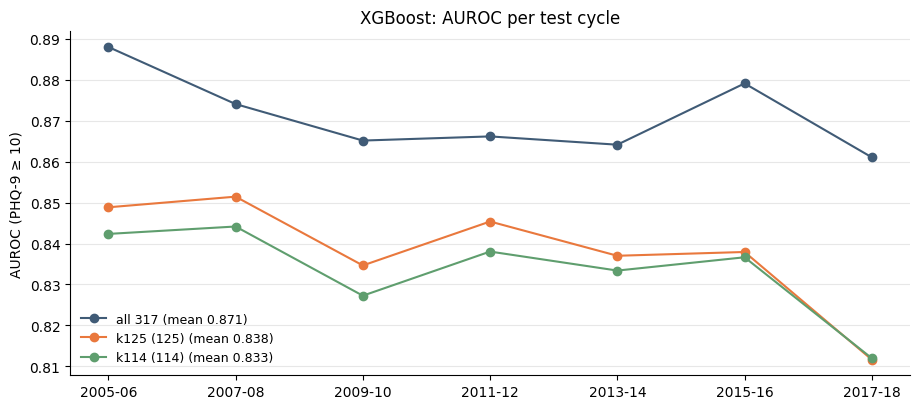

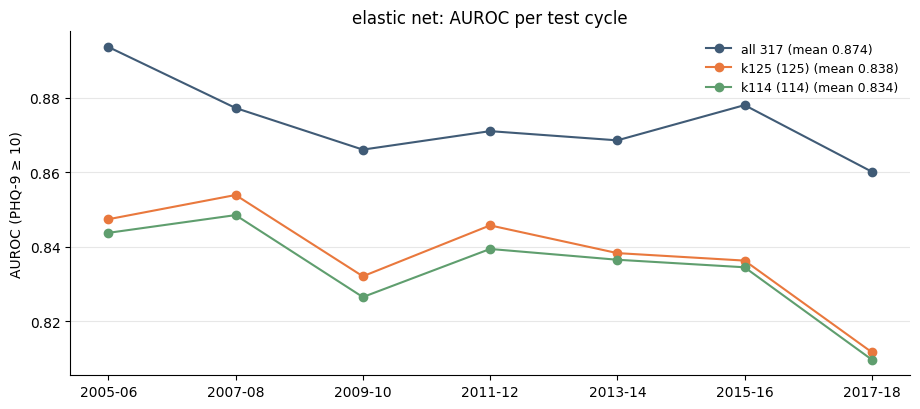

In [7]:
for model, name in [("xgboost", "XGBoost"), ("logreg", "elastic net")]:
    m = met[met.model == model].drop(columns="model").rename(columns={"features": "model"})
    plots.per_split_auroc(m, title=f"{name}: AUROC per test cycle")
    plots.show()